In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
from scipy.optimize import minimize
#from collections import defaultdict
from scipy import ndimage
import math
import glob, os
import scipy.optimize as optimize
from matplotlib.colors import LogNorm

#ploting
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter

def flux_uJy_to_Wm(wl,flux) :
    return np.array(flux)/(333564095198152064*np.array(wl)**2)

def flux_Wm_to_uJy(wl,flux) :
    return np.array(flux)*(333564095198152064*np.array(wl)**2)

In [22]:
#betelgeuse
pixscale = 0.11
pixtosr = (pixscale/(3600*180/np.pi))**2 
print(flux_Wm_to_uJy(23.00,0.00002)*1e-3*pixtosr,'mJy per pixel')
print(flux_Wm_to_uJy(23.00,0.00002)*1e-12,'MJy per sr')

1.0036910897719225 mJy per pixel
3529.108127196449 MJy per sr


In [18]:
pixscale = 0.11
pixtosr = (pixscale/(3600*180/np.pi))**2 

print(flux_Wm_to_uJy(10.50,1.0)*1e-6*pixtosr)

10.459068303152593


In [3]:
print(flux_Wm_to_uJy(10.65,3.6e-19))
print(flux_Wm_to_uJy(15.50,1.2e-19))
print(flux_Wm_to_uJy(7.7,1.49e-19))

print(flux_Wm_to_uJy(15.0,2.7e-20))

13.620122491540467
9.616652864562726
2.946775265440467
2.0264018783287736


Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224
Loading of 9 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 288 / 224


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  1.55
max:  16624.117 Y:  156 X:  156 sigma:  1.55


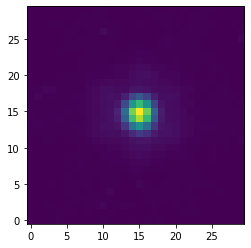

Roll - TA 1
Result : A = 16722.1 / x0 = 155.96 / y0 = 155.71 / width_x = 1.38 / width_y = 1.45
Stddev : A = 62.1 / x0 = 0.01 / y0 = 0.01 / width_x = 0.01 / width_y = 0.01
max:  16019.845 Y:  115 X:  117 sigma:  1.55


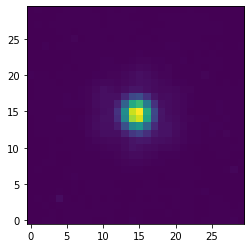

Roll - TA 2
Result : A = 16907.6 / x0 = 116.65 / y0 = 114.64 / width_x = 1.36 / width_y = 1.44
Stddev : A = 55.6 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
max:  156770.08 Y:  157 X:  156 sigma:  1.55


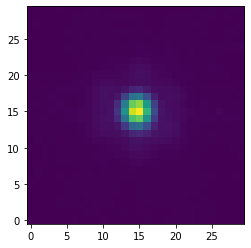

Ref - TA 1
Result : A = 162998.1 / x0 = 155.66 / y0 = 157.05 / width_x = 1.39 / width_y = 1.45
Stddev : A = 227.6 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
max:  149724.67 Y:  115 X:  117 sigma:  1.55


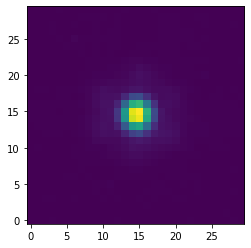

Ref - TA 2
Result : A = 164010.9 / x0 = 116.61 / y0 = 114.57 / width_x = 1.38 / width_y = 1.45
Stddev : A = 225.3 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  1.55
max:  16323.744 Y:  156 X:  156 sigma:  1.55


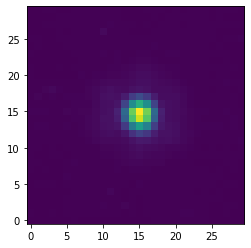

Roll - TA 1
Result : A = 16783.8 / x0 = 156.02 / y0 = 155.59 / width_x = 1.38 / width_y = 1.44
Stddev : A = 51.7 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
max:  15935.742 Y:  115 X:  117 sigma:  1.55


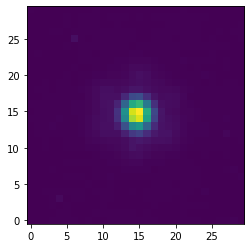

Roll - TA 2
Result : A = 16976.9 / x0 = 116.64 / y0 = 114.63 / width_x = 1.36 / width_y = 1.43
Stddev : A = 48.9 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
max:  156770.08 Y:  157 X:  156 sigma:  1.55


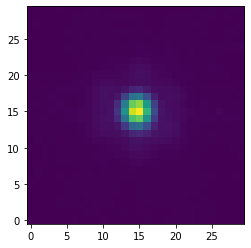

Ref - TA 1
Result : A = 162998.1 / x0 = 155.66 / y0 = 157.05 / width_x = 1.39 / width_y = 1.45
Stddev : A = 227.6 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
max:  149724.67 Y:  115 X:  117 sigma:  1.55


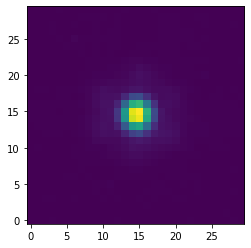

Ref - TA 2
Result : A = 164010.9 / x0 = 116.61 / y0 = 114.57 / width_x = 1.38 / width_y = 1.45
Stddev : A = 225.3 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
f_scale_1 with TA :  0.10161757341613327
f_scale_2 with TA :  0.10123803225796159


In [2]:
################
#### F1140C ####
################


path_save = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327/'

if not os.path.exists(path_save):
    os.makedirs(path_save)

pixscale = 0.110 # arcsec
filt='F1140C'

if filt == 'F1065C':
    lam = 10.65e-6    # lambda en m
    x0  = 120.25
    y0  = 112.03

if filt == 'F1140C':
    lam = 11.40e-6    # lambda en m
    x0  = 119.77
    y0  = 112.16

if filt == 'F1550C':
    lam = 15.50e-6    # lambda en m
    x0  = 119.71
    y0  = 113.28


aff  = 'cal'

path_tar_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs006/'
path_tar_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs007/'
path_ref    = '/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P03662/obs009/'

path_bkg_1  = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs008/'
path_bkg_2  = '/home/cperrot/Work/raw/JWST/Target/MAST/MASTER_BKG/P03662/obs010/'


cube_tar_1 ,header_tar_1   = imp.load_cube(path_tar_1,aff)
cube_tar_2 ,header_tar_2   = imp.load_cube(path_tar_2,aff)
cube_ref   ,header_ref     = imp.load_cube(path_ref,aff)
 
min_bkg_1 = fits.open(glob.glob(path_bkg_1+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data
min_bkg_2 = fits.open(glob.glob(path_bkg_2+'P*_master_bkg_cal.fits',recursive=False)[0])[0].data
    
#bkg subtraction
cube_tar_1 = cube_tar_1-min_bkg_1
cube_tar_2 = cube_tar_2-min_bkg_1
cube_ref   = cube_ref-min_bkg_2


imp.save_fits(cube_tar_1,path_save+'HD181327_roll1_bkg_subtracted.fits')
imp.save_fits(cube_tar_2,path_save+'HD181327_roll2_bkg_subtracted.fits')
imp.save_fits(cube_ref,path_save+'HD181327_ref_bkg_subtracted.fits')



if False:
    ### write SCI and REF fits after minimum bkg subtraction  
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_tar_1[0]),fits.ImageHDU(data=cube_tar_1,header=header_tar_1[0])])
    hdu_list.writeto(path_save+'HD181327_roll-1_dither1_minimum_bkg_cal.fits',overwrite=True)
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_tar_2[0]),fits.ImageHDU(data=cube_tar_2,header=header_tar_2[0])])
    hdu_list.writeto(path_save+'HD181327_roll-2_dither1_minimum_bkg_cal.fits',overwrite=True)
    hdu_list = fits.HDUList([fits.PrimaryHDU(header=header_ref[0][0]),fits.ImageHDU(data=cube_ref,header=header_ref[0][1])])
    hdu_list.writeto(path_save+'REF_HD203010_dither1-9_minimum_bkg_cal.fits',overwrite=True)  


clipval = 3.
cube_tar_1  = imp.sigma_clip_jwst(cube_tar_1,clipval)
cube_tar_2  = imp.sigma_clip_jwst(cube_tar_2,clipval)
cube_ref    = imp.sigma_clip_jwst(cube_ref,clipval)

cube_tar_1 = imp.clean_image_nan(cube_tar_1)
cube_tar_2 = imp.clean_image_nan(cube_tar_2)
cube_ref = imp.clean_image_nan(cube_ref)

#resize
newd = 201
xd = np.shape(cube_tar_1)[1]
yd = np.shape(cube_tar_1)[0]
scale=[(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]

cube_tar_1 = ndimage.shift(cube_tar_1,[newd/2-y0,newd/2-x0])
cube_tar_2 = ndimage.shift(cube_tar_2,[newd/2-y0,newd/2-x0])
for i in range(len(cube_ref)): cube_ref[i,:,:] = ndimage.shift(cube_ref[i,:,:],[newd/2-y0,newd/2-x0])
y0 = newd/2
x0 = newd/2

cube_tar_1 = cube_tar_1[int(y0-newd/2):int(y0+newd/2),int(x0-newd/2):int(x0+newd/2)]
cube_tar_2 = cube_tar_2[int(y0-newd/2):int(y0+newd/2),int(x0-newd/2):int(x0+newd/2)]
cube_ref   = cube_ref[:,int(y0-newd/2):int(y0+newd/2),int(x0-newd/2):int(x0+newd/2)]



#PCA # commented because PCA is bad for this target
#PCA_1140_1 = imp.sub_PCA(cube_tar_1, cube_ref, [newd//2,newd//2], 2, dim=newd//2, plot=False)
#PCA_1140_2 = imp.sub_PCA(cube_tar_2, cube_ref, [newd//2,newd//2], 2, dim=newd//2, plot=False)

# flux scaling for RDI
f_scale_1 = imp.flux_scaling_ta(path_tar_1+'TA', path_ref+'TA', aff, lam)
f_scale_2 = imp.flux_scaling_ta(path_tar_2+'TA', path_ref+'TA', aff, lam)
print("f_scale_1 with TA : ",f_scale_1)
print("f_scale_2 with TA : ",f_scale_2)

#perform RDI 
RDI_1140_1 = imp.RDI_classic(cube_tar_1, cube_ref, f_scale=f_scale_1)
RDI_1140_2 = imp.RDI_classic(cube_tar_2, cube_ref, f_scale=f_scale_2)

#subshift for roll 1
#RDI_1140_1 = RDI_classic(ndimage.shift(clean_image_nan(cube_tar_1),[0.0,0.1]), clean_image_nan(cube_ref), f_scale=f_scale_1)

#rotation
PA_V3_1 = header_tar_1[1]['PA_V3']     # 59.58852013851359
V3i_1   = header_tar_1[1]['V3I_YANG']  # 4.83544897
PA_V3_2 = header_tar_2[1]['PA_V3']     # 66.59658743620635
V3i_2   = header_tar_2[1]['V3I_YANG']  # 4.83544897

#PCA_1140_1 = ndimage.rotate(PCA_1140_1, -(PA_V3_1+V3i_1), reshape=False)
#PCA_1140_2 = ndimage.rotate(PCA_1140_2, -(PA_V3_2+V3i_2), reshape=False)
RDI_1140_1_c = np.copy(RDI_1140_1)
RDI_1140_2_c = np.copy(RDI_1140_2)
RDI_1140_1_c = imp.clean_image_nan(RDI_1140_1_c)
RDI_1140_2_c = imp.clean_image_nan(RDI_1140_2_c)
RDI_1140_1_r = ndimage.rotate(RDI_1140_1_c, -(PA_V3_1+V3i_1), reshape=False)
RDI_1140_2_r = ndimage.rotate(RDI_1140_2_c, -(PA_V3_2+V3i_2), reshape=False)

##PCA_1140_t = (PCA_1140_1+PCA_1140_2)/2.
RDI_1140_t   = (RDI_1140_1+RDI_1140_2)/2.
RDI_1140_t_c = (RDI_1140_1_c+RDI_1140_2_c)/2.
RDI_1140_t_r = (RDI_1140_1_r+RDI_1140_2_r)/2.


imp.save_fits(RDI_1140_1,path_save+'RDI_1140_roll_1.fits')
imp.save_fits(RDI_1140_2,path_save+'RDI_1140_roll_2.fits')
imp.save_fits(RDI_1140_t,path_save+'RDI_1140_somme_roll.fits')
imp.save_fits(RDI_1140_1_r,path_save+'RDI_1140_roll_1_rot.fits')
imp.save_fits(RDI_1140_2_r,path_save+'RDI_1140_roll_2_rot.fits')
imp.save_fits(RDI_1140_t_r,path_save+'RDI_1140_somme_roll_rot.fits')

imp.save_fits(cube_tar_1,path_save+'cube_1140_pixelcorr_1.fits')
imp.save_fits(cube_tar_2,path_save+'cube_1140_pixelcorr_2.fits')

imp.save_fits(RDI_1140_1_c,path_save+'RDI_1140_roll_1_clean.fits')
imp.save_fits(RDI_1140_2_c,path_save+'RDI_1140_roll_2_clean.fits')
imp.save_fits(RDI_1140_t_c,path_save+'RDI_1140_somme_roll_clean.fits')
imp.save_fits(imp.clean_image_nan(cube_tar_1),path_save+'cube_1140_pixelcorr_1_clean.fits')
imp.save_fits(imp.clean_image_nan(cube_tar_2),path_save+'cube_1140_pixelcorr_2_clean.fits')




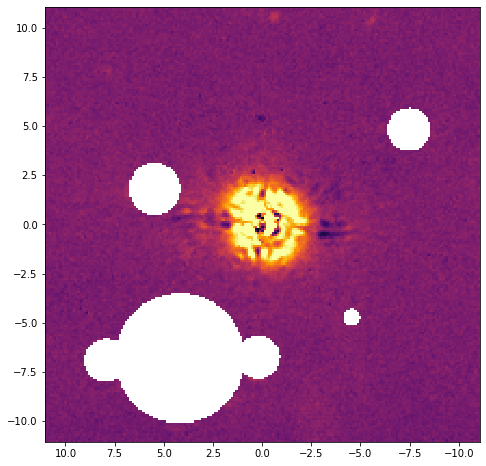

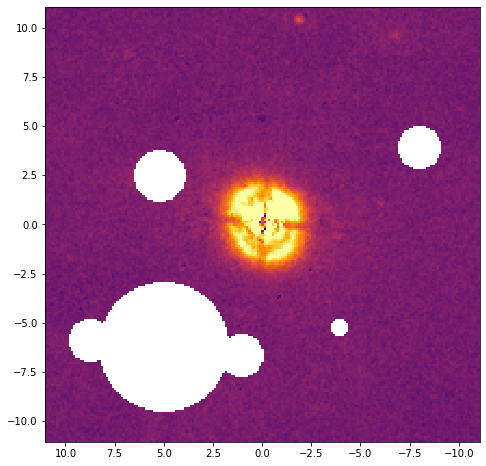

In [4]:
image1  = RDI_1140_1_c.copy()  # roll 1 RDI
image2  = RDI_1140_2_c.copy()  # roll 2 RDI

ydim = np.shape(image1)[-2]
xdim = np.shape(image1)[-1]

x0=xdim/2
y0=ydim/2
Y, X = np.ogrid[:ydim, :xdim]
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

# transmission
path_transmission = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
transmi_sum = fits.open(path_transmission+'F1140C_transmi_sum.fits')[0].data

### Transmission à 45° (optimale)

t_sum_45 = transmi_sum.copy()
t_sum_45 = ndimage.rotate(t_sum_45, 45.-V3i_1, reshape=False)
t_sum_45 = t_sum_45[ydim//2,xdim//2:]

### Transmission à 0° (pas optimale)

t_sum_0 = transmi_sum.copy()
t_sum_0 = ndimage.rotate(t_sum_0, 0.-V3i_1, reshape=False)
t_sum_0 = t_sum_0[ydim//2,xdim//2:]

dr = 1.5*lam/6.5*180.*3600./np.pi/pixscale #pour faire une zone de 1,5*2 = 3 L/D de diametre

#### masks for background objects (galaxies, stars)

xcoord_2 = np.array([+48,-72,+46,+10,+80,-35])
ycoord_2 = np.array([-22,-35,+57,+61,+54,+48])
sizemask = np.array([12 , 10, 30, 10, 10, 4 ])

mask_bkg_obj_2 = np.sqrt((X - x0)**2 + (Y-y0)**2) >= 0

for i in range(len(sizemask)): mask_bkg_obj_2 *= (np.sqrt((X - x0 + xcoord_2[i])**2 + (Y - y0 + ycoord_2[i])**2) > sizemask[i] )

    
xcoord_1 = np.sqrt(xcoord_2**2 + ycoord_2**2)*np.cos(np.arctan2(ycoord_2, xcoord_2)-(PA_V3_1-PA_V3_2)*np.pi/180.)
ycoord_1 = np.sqrt(xcoord_2**2 + ycoord_2**2)*np.sin(np.arctan2(ycoord_2, xcoord_2)-(PA_V3_1-PA_V3_2)*np.pi/180.)


mask_bkg_obj_1 = np.sqrt((X - x0)**2 + (Y-y0)**2) >= 0
for i in range(len(sizemask)): mask_bkg_obj_1 *= (np.sqrt((X - x0 + xcoord_1[i])**2 + (Y - y0 + ycoord_1[i])**2) > sizemask[i] )


### supprimer manuellement les pixels mort restant 
pixel_mort=[[66,108],[57,107],[79,123],[81,143],[93,136],[117,137],[129,137],[98,77],[83,105],[91,90],[90,91],[91,92]]
for i in pixel_mort:
    image1[i[0],i[1]] = math.nan
    image2[i[0],i[1]] = math.nan
imp.clean_image_nan(image1)
imp.clean_image_nan(image2)

#sum_img = (image1+image2)/2.


### Std dev local dans 3 L/D pour chaque pixel hors bords sur 2 pixels
std_psf_1   = np.ndarray([ydim,xdim]) ### Roll 1
std_psf_2   = np.ndarray([ydim,xdim]) ### Roll 2
#std_psf_sum = np.ndarray([ydim,xdim]) ### Sum Roll
for i in range(ydim):
    for j in range(xdim):
        #if (i < 2) or (j < 2) or (i > ydim-3) or (j > xdim-3):
        #    std_psf_1[i,j] = 0.
        #    std_psf_2[i,j] = 0.
            #std_psf_sum[i,j] = 0.
        #else:
        mask_psf = np.sqrt((X -j)**2 + (Y -i)**2) <= dr
        std_psf_1[i,j] = np.nanstd(image1[mask_psf])
        std_psf_2[i,j] = np.nanstd(image2[mask_psf])
        #std_psf_sum[i,j] = np.nanstd(sum_img[mask_psf])


#sum_img[np.where(mask_bkg_obj == 0)] = math.nan
image1[np.where(mask_bkg_obj_1 == 0)] = math.nan
image2[np.where(mask_bkg_obj_2 == 0)] = math.nan

plt.figure(figsize=(8,8))
plt.imshow(image1,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()
plt.figure(figsize=(8,8))
plt.imshow(image2,origin='lower',cmap='inferno',interpolation='none',vmin=-1,vmax=2,extent=scale)
plt.show()

mask_pla   = np.sqrt((X - x0 + 0.5)**2 + (Y - y0 + 0.5)**2)

### Std dev azimutale dans un anneau de 3 L/D de largeur
std_1    = np.ndarray(xdim//2)
std_2    = np.ndarray(xdim//2) ### pour roll 2
#std_sum  = np.ndarray(xdim//2) ### pour sum
std_map_1 = np.ndarray([xdim,xdim])*0.
std_map_2 = np.ndarray([xdim,xdim])*0.
mask_map = np.ndarray([xdim//2,xdim,xdim])*0.
for i in range(0,xdim//2):
    mask_sel  = (mask_pla >= i-dr) * (mask_pla < i+dr)
    mask_map[i,:,:] = mask_sel*image2 #sum_img
    std_1[i]    = np.nanstd(image1[mask_sel])  ### radial pour roll 1
    std_2[i]    = np.nanstd(image2[mask_sel])  ### radial pour roll 2
 #   std_sum[i]  = np.nanstd(sum_img[mask_sel]) ### radial pour sum
    std_map_1[mask_sel] = std_1[i]            ### MAP pour roll 1
    std_map_2[mask_sel] = std_2[i]            ### MAP pour roll 2

imp.save_fits(mask_map,path_save+'mask_map.fits')
imp.save_fits(mask_pla,path_save+'mask_pla.fits')


    
    
    

### Calcul pour passer de 1 Sr de surface a 1 pixel de surface
# 1 pixel = pixscale**2 in arcsec
# 1 radian = 3600*180/pi arcsec
# 1 sr = radian**2
# 1 pixel in sr = (pixscale/(3600*180/np.pi))**2
#print("1 pixel in sr = ",(pixscale/(3600*180/np.pi))**2)
pixtosr = (pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
mjytoujy = 1e12                          #Mjy to µjy
nbpixel = np.pi*dr**2                    #nombre de pixel dans la zone de photométrie de "dr" l/D de rayon 
coef=pixtosr*mjytoujy*np.sqrt(nbpixel)*2.0887366235130878 # 2.0887366235130878 facteur de correction d'ouverture obtenu avec STPSF : flux in 1.5L/D / flux in the image


### passage de µJy a W/m2/µm (les flux sont en MJy/sr mais le facteur de conversion est linéaire et donc peut être fait plus tard)
std_1_wm   = flux_uJy_to_Wm(11.4,std_1)
std_2_wm   = flux_uJy_to_Wm(11.4,std_2)
#std_sum_wm = flux_uJy_to_Wm(11.4,std_sum)

### map 5 Sigma std dev en microjy par pixel avec correction de la transmission (profil radial / transmission)
imp.save_fits(5*coef*std_map_1/transmi_sum,path_save+'HD181327_std_ujy_roll1_transmi_sum.fits')
imp.save_fits(5*coef*std_map_2/transmi_sum,path_save+'HD181327_std_ujy_roll2_transmi_sum.fits')

### pareil mais en W.m-2 par pixel
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_map_1)/transmi_sum,path_save+'HD181327_map_std_wm2_roll1_transmi_sum.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_map_2)/transmi_sum,path_save+'HD181327_map_std_wm2_roll2_transmi_sum.fits')

### 5 sigmae std dev avec zone de 3 L/D conlissante sur chaque pixel (c'est pas ouf) corrigé de la transmission
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_psf_1)/transmi_sum,path_save+'HD181327_std_wm2_roll1_transmi_sum.fits')
imp.save_fits(5*coef*flux_uJy_to_Wm(11.4,std_psf_2)/transmi_sum,path_save+'HD181327_std_wm2_roll2_transmi_sum.fits')
#imp.save_fits((flux_uJy_to_Wm(11.4,std_psf_sum)*coef*5)/transmi_sum*mask_bkg_obj,path_save+'HD181327_std_psf_wm2_transmi_sum.fits')



lim_det_5sig_t0_wm = np.ndarray(xdim//2)
lim_det_5sig_t45_wm = np.ndarray(xdim//2)
file = open(path_save+"lim_det_wm2_HD181327_F1140_P3662_007_RDI.dat","w")
for i in range(0,xdim//2):
    #print("{:4.3f}".format((i+0.5)*0.11),"{:4.3f}".format(coef*std_m2[i]),"{:.3e}".format(coef*std_m2_wm[i]))
    lim_det_5sig_t0_wm[i]  = 5*coef*std_2_wm[i]/t_sum_0[i]
    lim_det_5sig_t45_wm[i] = 5*coef*std_2_wm[i]/t_sum_45[i]
    file.write("{:4.3f}".format(i*0.11)+" {:.3e}".format(lim_det_5sig_t0_wm[i])+" {:.3e}".format(lim_det_5sig_t45_wm[i])+"\n")
file.close()


#roll1_map_wm_sum = 5*coef*flux_uJy_to_Wm(11.4,std_map_1)/transmi_sum
#roll2_map_wm_sum = 5*coef*flux_uJy_to_Wm(11.4,std_map_2)/transmi_sum

#roll1_map_wm_sum[np.where(np.isnan(roll1_map_wm_sum))] = 0
#roll2_map_wm_sum[np.where(np.isnan(roll2_map_wm_sum))] = 0

#roll1_map_wm_sum = ndimage.rotate(roll1_map_wm_sum, -PA_V3_1, reshape=False)
#roll2_map_wm_sum = ndimage.rotate(roll2_map_wm_sum, -PA_V3_2, reshape=False)

#imp.save_fits(roll1_map_wm_sum, path_save+'HD181327_roll1_det_lim_map_wm_tsum.fits')
#imp.save_fits(roll2_map_wm_sum, path_save+'HD181327_roll2_det_lim_map_wm_tsum.fits')



In [4]:
saveformat = "pdf"

fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*std_map_2/transmi_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [µJy]')
fig1.savefig(path_save+'HD181327_std_ujy_roll2_transmi_sum.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)



fig1 = plt.figure(figsize=(10,10))
tmp = plt.imshow(5*coef*flux_uJy_to_Wm(11.4,std_map_2)/transmi_sum,origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(),extent=scale)
cbar = fig1.colorbar(tmp)
cbar.set_label(r'5$\sigma$ Detection limit map [µJy]')
fig1.savefig(path_save+'HD181327_std_wm2_roll2_transmi_sum.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)



fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0.5,xdim//2,1)*0.11,std_1/std_2,'black',label='Ratio Std Dev roll 1/2')
plt.title('Ratio Std Dev')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'Ratio')
plt.ylim([0,3])
plt.grid()
plt.legend()
fig1.savefig(path_save+'HD181327_ratio_stddev.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)

fig1 = plt.figure(figsize=(10,10))
plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_1/t_sum_45[:-1],'green',label='Roll 1 - 45°')
plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_2/t_sum_45[:-1],'blue',label='Roll 2 - 45°')
#plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_sum/t_sum_45,'red',label='Mean - 45°')
plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_2/t_sum_0[:-1],'violet',label='Roll 2 - 0°')
plt.title(r'Std Dev - 5$\sigma$')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'5$\sigma$ Detection limit [µJy]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.grid(True, which="major", ls="-")
plt.grid(True, which="minor", ls="--")
plt.ylim([1e0,1e4])
plt.xlim([0,11])
plt.legend()
fig1.savefig(path_save+'HD181327_stddev_ujy.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)




fig1 = plt.figure(figsize=(10,7))
plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_1_wm/t_sum_45[:-1],'green',label='Roll 1 - 45°')
plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_2_wm/t_sum_45[:-1],'blue',label='Roll 2 - 45°')
#plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_sum_wm/t_sum_45,'red',label='Mean - 45°')
plt.plot(np.arange(0.5,xdim//2,1)*0.11,5*coef*std_2_wm/t_sum_0[:-1],'violet',label='Roll 2 - 0°')
plt.title(r'Std Dev - 5$\sigma$')
plt.xlabel('Separation [arcsec]')
plt.ylabel(r'5$\sigma$ Detection limit [W.m$^{-2}.µm^{-1}$]')
#plt.ylabel(r'Flux [MJy.sr$^{-1}$]')
plt.yscale('log')
plt.grid(True, which="major", ls="-")
plt.grid(True, which="minor", ls="--")
plt.ylim([1e-20,1e-16])
plt.xlim([0,11])
plt.legend()
fig1.savefig(path_save+'HD181327_stddev_wm2.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig1)




In [5]:
### limite de detection avec fausse planète STPSF


image1  = RDI_1140_1_c.copy()  # roll 1 RDI
image2  = RDI_1140_2_c.copy()  # roll 2 RDI

ydim = np.shape(image1)[-2]
xdim = np.shape(image1)[-1]
scale=[(xdim/2.)*pixscale,-1*(xdim/2.)*pixscale,-1*(ydim/2.)*pixscale,(ydim/2.)*pixscale]

x0=xdim//2
y0=ydim//2

stpsf = fits.open('/home/cperrot/Work/raw/JWST/STPSF/F1140C_PSF/F1140C_PSF_2500_2500mas.fits')[0].data

pixtosr = (pixscale/(3600*180/np.pi))**2 # y avait un facteur 6^2 et je sais pas pourquoi. Erreur ?
mjytoujy = 1e12 #Mjy to µjy
coef_f=pixtosr*mjytoujy

# transmission
path_transmission = '/home/cperrot/Work/projet/JWST/Target/GO/P3662/output_with_photom/HD181327/'
transmi_sum = fits.open(path_transmission+'transmi_sum.fits')[0].data
transmi_img1=transmi_sum[87,103] #position of the planet in roll 1
transmi_img2=transmi_sum[87,102] #position of the planet in roll 2

dr = 1*lam/6.5*180.*3600./np.pi/pixscale
Y, X = np.ogrid[:ydim, :xdim]

#Mise en forme de la PSF STPSF

mask_psf  = np.sqrt((X - x0-22)**2 + (Y-y0-22)**2) < 1.5*dr
mask_psf2 = np.sqrt((X - x0-22)**2 + (Y-y0-22)**2) < 3.5*dr

if False:
    plt.imshow((stpsf*mask_psf)[x0+round(2.5/pixscale)-10:x0+round(2.5/pixscale)+10,y0+round(2.5/pixscale)-10:y0+round(2.5/pixscale)+10],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=0.01,extent=scale)
    plt.show()
    plt.imshow((mask_psf)[x0+round(2.5/pixscale)-10:x0+round(2.5/pixscale)+10,y0+round(2.5/pixscale)-10:y0+round(2.5/pixscale)+10],origin='lower',cmap='inferno',interpolation='none',vmin=0,vmax=0.01,extent=scale)
    plt.show()

    print('flux STPSF in 1.5L/D radius : ',np.sum(stpsf[mask_psf]))
    print('flux STPSF in 3.5L/D radius : ',np.sum(stpsf[mask_psf2]))
    print('flux STPSF in the whole image : ',np.sum(stpsf))

    plt.imshow((stpsf),origin='lower',cmap='inferno',interpolation='none',norm=LogNorm(vmin=1e-8, vmax=1e-2))#,vmin=0,vmax=0.01,extent=scale)
    plt.show()

norm = np.sum(stpsf)
stpsf /= norm

if False:
    print('flux STPSF in 1.5L/D radius : ',np.sum(stpsf[mask_psf]))
    print('flux STPSF in 3.5L/D radius : ',np.sum(stpsf[mask_psf2]))
    print('flux STPSF in the whole image : ',np.sum(stpsf))

    plt.imshow((image1-ndimage.shift(stpsf*100,[-13.5,-13.2]))[x0-0:x0+30,y0-0:y0+30],origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=3.5,extent=scale)
    plt.show()
    print('img 1 flux STPSF norm in 1.5L/D radius : ',flux_uJy_to_Wm(11.4,coef_f*np.sum(57*stpsf[mask_psf]))/transmi_img1)

    plt.imshow((image2-ndimage.shift(stpsf*100,[-13,-13.5]))[x0-0:x0+30,y0-0:y0+30],origin='lower',cmap='inferno',interpolation='none',vmin=-0.5,vmax=3.5,extent=scale)
    plt.show()
    print('img 2 flux STPSF norm in 1.5L/D radius : ',flux_uJy_to_Wm(11.4,coef_f*np.sum(40*stpsf[mask_psf]))/transmi_img2)



stpsf_cen = ndimage.shift(stpsf,[-22.62,-22.5])

if False:
    plt.figure(figsize=(4,4))
    plt.imshow(stpsf_cen[x0-10:x0+10,y0-10:y0+10],origin='lower',cmap='inferno',interpolation='none',vmin=-0.025,vmax=0.032) 
    plt.show()


sep_i = 30


fake_pla = ndimage.shift(stpsf_cen,[sep_i/np.sqrt(2),sep_i/np.sqrt(2)])

nsig = 200.
a = nsig*std_2[sep_i]*coef/coef_f #pour prendre en compte l'impact du la taille de la psf où la mesure est faite

dx=30
plt.figure(figsize=(6,6))
plt.imshow((image2+fake_pla*a)[x0-dx:x0+dx,y0-dx:y0+dx],origin='lower',cmap='inferno',interpolation='none',vmin=-0.35,vmax=10.55) #[x0-9:x0+11,y0-9:y0+11]
plt.show()

print('Flux en MJy/sr : ',a)
print('Lim det en W/m2/µm : ',flux_uJy_to_Wm(11.4,a*coef_f)/t_sum_45[sep_i])


plt.figure(figsize=(4,4))
plt.imshow(stpsf*mask_psf,origin='lower',cmap='inferno',interpolation='none',vmin=-0,vmax=0.05) 
plt.show()





ValueError: operands could not be broadcast together with shapes (201,201) (200,200) 

<Figure size 432x432 with 0 Axes>

In [95]:
a*coef_f

2.131931776395937